# IoMT-TrafficData Dataset – Exploration & Analysis

**Diploma Thesis**: IoT/IoMT Network Intrusion Detection  
**Dataset**: IoMT-TrafficData – ML-Based IDS for Internet of Medical Things  
**Reference**: Areia et al. (2024), *IEEE Access*, Vol. 12, pp. 115370–115385  
**Source**: Zenodo DOI 10.5281/zenodo.8116337  

---

## Table of Contents

1. [Dataset Overview & Methodology](#1-dataset-overview--methodology)
2. [Imports & Configuration](#2-imports--configuration)
3. [Data Loading](#3-data-loading)
4. [Basic Statistics](#4-basic-statistics)
5. [Feature Analysis](#5-feature-analysis)
6. [Label Analysis & Attack Taxonomy](#6-label-analysis--attack-taxonomy)
7. [Packet vs Flow Comparison Note](#7-packet-vs-flow-comparison-note)
8. [Summary & Key Findings](#8-summary--key-findings)

## 1. Dataset Overview & Methodology

### Dataset Description

**IoMT-TrafficData** is an IoMT network traffic dataset for benchmarking ML-based intrusion detection. It was introduced by Areia et al. (2024) and provides **benign** and **malicious** traffic with features built over **packet** and **network flow** information.

### Key Characteristics

| Characteristic | Value |
|---|---|
| **Attack types** | 8 (plus Benign) |
| **Protocols** | CoAP, MQTT, HTTP |
| **Capture approaches** | Packet-level and flow-level |
| **Flow feature source** | Zeek (flow/conn-style statistics) |
| **Device types** | 10+ IoMT devices |
| **Format** | PCAP → CSV (per attack/benign) |

### Attack Types (8)

| Attack | Description (paper) |
|---|---|
| **ARP Spoofing** | MAC falsification, traffic redirection |
| **Apache Killer** | DoS variant |
| **CAM Table Overflow** | MAC flooding on switch |
| **MQTT Malaria** | Flooding MQTT broker with illegitimate requests |
| **Reconnaissance (Netscan)** | Information gathering (e.g. Net Scan) |
| **R-U-Dead-Yet (RUDY)** | DoS (slow POST) |
| **Slow Loris** | DoS (slow HTTP) |
| **Slow Read** | DoS (slow read) |

### Methodology (from paper)

- **Packet-oriented**: data over individual segments traversing the network.
- **Flow-oriented**: data on sequences of packets sharing common characteristics or the same session.
- The paper reports that **flow-based features** achieve on average **up to ~5% better performance** than packet-based features for ML-based IDS.
- Dataset supports **binary** (benign vs malicious) and **multiclass** (attack type) classification.

### Note on Our Analysis

This notebook uses the **flow-level CSV** files from the dataset (IP-Based Flows). Packet-level CSVs are larger and available in the full Zenodo archive; the flow-level data are sufficient for integration and comparison with other flow/window-based datasets (CICIoT2023, CICIoMT2024).

## 1b. Zeek Flow Features vs DPKT Window-Based Features

Understanding the **fundamental difference** in feature extraction between this dataset and the CIC datasets (CICIoT2023 / CICIoMT2024) is critical for the integration pipeline.

### What is Zeek?

**Zeek** (formerly Bro) is a powerful open-source network analysis framework. Unlike simple packet capture tools, Zeek monitors network traffic and produces **structured, high-level logs** of network activity. Its `conn.log` is the primary source for flow-level features:

- Each row represents a **completed network connection** (a full bidirectional flow between two endpoints).
- Features include connection metadata (`id.orig_h`, `id.resp_h`, `proto`, `service`), byte/packet counts (`orig_bytes`, `resp_bytes`, `orig_pkts`, `resp_pkts`), connection state (`conn_state`, `history`), and timing information (`duration`).
- The IoMT-TrafficData authors **extended** the base Zeek conn.log with additional flow statistics: forward/backward packet metrics (`fwd_*`, `bwd_*`), inter-arrival times (`fwd_iat`, `bwd_iat`, `flow_iat`), payload statistics, flag counts, bulk metrics, window sizes, and active/idle periods.

### What is DPKT Window-Based Extraction?

The **CIC datasets** (CICIoT2023 and CICIoMT2024) use a completely different approach:

- Raw PCAP files are processed using the **DPKT** Python library.
- Packets are grouped into **fixed-size windows** (10 or 100 consecutive packets).
- For each window, **aggregate statistics** are computed (mean values of packet-level features).
- The resulting features are abstract statistical summaries: `Header_Length`, `Rate`, `Tot sum`, `Min`, `Max`, `AVG`, `Std`, `IAT`, `Number`, `Variance`, plus protocol indicator flags (`HTTP`, `HTTPS`, `DNS`, `TCP`, `UDP`, etc.) and TCP flag counts.

### Key Differences

| Aspect | Zeek (IoMT-TrafficData) | DPKT Windows (CIC datasets) |
|---|---|---|
| **Unit of analysis** | Complete network flow/connection | Fixed window of 10 or 100 packets |
| **Feature source** | Zeek conn.log + extended statistics | DPKT packet parsing + aggregation |
| **Number of features** | 101 | 39–45 |
| **Feature semantics** | Per-flow statistics (bytes, packets, IAT, flags per direction) | Per-window mean values (abstract aggregates) |
| **Directionality** | Explicit fwd/bwd separation | No explicit directional breakdown |
| **IP/port information** | Preserved (id.orig_h, id.resp_h, ports) | Not preserved in CSVs |
| **Connection state** | Preserved (conn_state, history) | Not available |

### Implications for Integration

1. **Direct column-matching is not possible** — the feature sets are semantically different.
2. **Semantic feature mapping** is required: identify features that capture the same network property (e.g., `flow_duration` ↔ derived from `IAT` × `Number`; `fwd_pkts_tot` ↔ related to `Number`; flag counts exist in both but at different granularity).
3. This dataset serves as the **second IoMT-specific source** and strengthens the IoMT domain representation, even if integration requires more effort than the CIC-to-CIC merge.
4. An alternative strategy is to use this dataset as a **separate evaluation benchmark** for IoMT-trained models.

## 2. Imports & Configuration

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings

warnings.filterwarnings('ignore')

DATA_DIR = Path('../data/raw/IoMT-TrafficData/Flows')

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')
plt.rcParams.update({
    'figure.figsize': (14, 6),
    'figure.dpi': 100,
    'font.size': 11,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
})

print('Configuration loaded.')
print(f'Data directory: {DATA_DIR} (exists: {DATA_DIR.exists()})')
if DATA_DIR.exists():
    files = sorted(DATA_DIR.glob('*.csv'))
    print(f'CSV files: {len(files)}')

Configuration loaded.
Data directory: ../data/raw/IoMT-TrafficData/Flows (exists: True)
CSV files: 9


## 3. Data Loading

Labels are derived from the **filename** (e.g. `Normal.csv` → Benign, `ARP.csv` → ARP Spoofing). The CSV also has an **`is_attack`** column for binary labels. We load all flow CSVs and add a **`label`** column for attack type.

In [2]:
def file_to_label(filename: str) -> str:
    """Map CSV filename to attack label (paper naming)."""
    name = Path(filename).stem
    mapping = {
        'Normal': 'Benign',
        'ARP': 'ARP_Spoofing',
        'ApacheKiller': 'Apache_Killer',
        'CAM': 'CAM_Table_Overflow',
        'Malaria': 'MQTT_Malaria',
        'Netscan': 'Reconnaissance',
        'RUDY': 'RUDY',
        'SlowLoris': 'Slow_Loris',
        'SlowRead': 'Slow_Read',
    }
    return mapping.get(name, name)


def load_flows(data_dir: Path, sample_frac: float = None, max_rows_per_file: int = None):
    """Load all flow CSVs; optionally sample for large files."""
    dfs = []
    file_info = []
    for f in sorted(data_dir.glob('*.csv')):
        label = file_to_label(f.name)
        if max_rows_per_file:
            df = pd.read_csv(f, nrows=max_rows_per_file)
        elif sample_frac and sample_frac < 1.0:
            df = pd.read_csv(f)
            if len(df) > 100_000:
                df = df.sample(frac=sample_frac, random_state=42)
        else:
            df = pd.read_csv(f)
        df['label'] = label
        df['source_file'] = f.name
        file_info.append({'file': f.name, 'label': label, 'rows': len(df)})
        dfs.append(df)
    combined = pd.concat(dfs, ignore_index=True) if dfs else pd.DataFrame()
    return combined, file_info


# Load with a cap per file to keep memory and runtime manageable (full load possible if needed)
MAX_ROWS = 200_000  # per file; remove or set None for full load
df_flows, file_info = load_flows(DATA_DIR, max_rows_per_file=MAX_ROWS)

print('File inventory (rows per file, after cap):')
for info in file_info:
    print(f"  {info['file']:25s} -> {info['label']:25s} rows: {info['rows']:,}")
print(f"\nTotal rows: {len(df_flows):,}")
print(f"Total columns: {len(df_flows.columns)}")

File inventory (rows per file, after cap):
  ARP.csv                   -> ARP_Spoofing              rows: 11,236
  ApacheKiller.csv          -> Apache_Killer             rows: 84,579
  CAM.csv                   -> CAM_Table_Overflow        rows: 200,000
  Malaria.csv               -> MQTT_Malaria              rows: 69,623
  Netscan.csv               -> Reconnaissance            rows: 200,000
  Normal.csv                -> Benign                    rows: 200,000
  RUDY.csv                  -> RUDY                      rows: 131,081
  SlowLoris.csv             -> Slow_Loris                rows: 63,608
  SlowRead.csv              -> Slow_Read                 rows: 9,014

Total rows: 969,141
Total columns: 103


## 4. Basic Statistics

Dimensions, dtypes, nulls, and duplicate check.

In [3]:
print('Dataset dimensions')
print('=' * 50)
print(f'Rows:    {df_flows.shape[0]:,}')
print(f'Columns: {df_flows.shape[1]}')

feature_cols = [c for c in df_flows.columns if c not in ('label', 'source_file')]
print(f'Feature columns: {len(feature_cols)}')

# Separate numeric vs non-numeric features
numeric_cols = df_flows[feature_cols].select_dtypes(include=[np.number]).columns.tolist()
non_numeric_cols = [c for c in feature_cols if c not in numeric_cols]
print(f'  Numeric features:     {len(numeric_cols)}')
print(f'  Non-numeric features: {len(non_numeric_cols)} → {non_numeric_cols}')

print('\nData types')
print('=' * 50)
print(df_flows.dtypes.value_counts())

print('\nNull counts')
print('=' * 50)
nulls = df_flows[feature_cols].isnull().sum()
nulls_nonzero = nulls[nulls > 0].sort_values(ascending=False)
if len(nulls_nonzero) > 0:
    print(nulls_nonzero.head(15))
    print(f'\nTotal null values: {nulls.sum():,}')
else:
    print('No nulls in feature columns.')

print('\nInfinity values')
print('=' * 50)
inf_counts = df_flows[numeric_cols].apply(lambda c: np.isinf(c).sum() if c.dtype != object else 0)
inf_nonzero = inf_counts[inf_counts > 0].sort_values(ascending=False)
if len(inf_nonzero) > 0:
    print(inf_nonzero)
    print(f'\nTotal infinity values: {inf_counts.sum():,}')
else:
    print('No infinity values found.')

print('\nDuplicate rows')
print('=' * 50)
n_dupes = df_flows.duplicated().sum()
pct_dupes = 100 * n_dupes / len(df_flows)
print(f'Duplicates: {n_dupes:,} ({pct_dupes:.2f}%)')

print('\nDescriptive statistics (numeric features, first 20)')
print('=' * 50)
df_flows[numeric_cols[:20]].describe().round(3)

Dataset dimensions
Rows:    969,141
Columns: 103
Feature columns: 101
  Numeric features:     88
  Non-numeric features: 13 → ['id.orig_h', 'id.resp_h', 'proto', 'service', 'duration', 'orig_bytes', 'resp_bytes', 'conn_state', 'local_orig', 'local_resp', 'history', 'tunnel_parents', 'traffic']

Data types
float64    56
int64      32
str        12
object      3
Name: count, dtype: int64

Null counts


No nulls in feature columns.

Infinity values


No infinity values found.

Duplicate rows


Duplicates: 6,434 (0.66%)

Descriptive statistics (numeric features, first 20)


,id.orig_p,id.resp_p,missed_bytes,orig_pkts,orig_ip_bytes,resp_pkts,resp_ip_bytes,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,fwd_pkts_per_sec,bwd_pkts_per_sec,flow_pkts_per_sec,down_up_ratio,fwd_header_size_tot,fwd_header_size_min,fwd_header_size_max,bwd_header_size_tot
count,969141.000,969141.000,969141.0,969141.000,969141.000,969141.000,969141.000,969141.000,969141.000,969141.000,969141.000,969141.000,969141.000,969141.000,969141.000,969141.000,969141.000,969141.000,969141.000,969141.000
mean,41070.264,14380.339,0.0,6.951,713.611,0.215,9.306,0.667,13.150,5.475,7.587,2.094,3770.201,3780.018,7550.219,0.704,406.180,21.588,22.998,166.824
std,16018.324,19665.850,0.0,26.444,2155.557,0.433,27.060,1.552,105.082,24.519,57.283,6.142,24693.396,24682.053,49370.571,0.536,3364.119,12.971,14.382,785.185
min,0.000,0.000,0.0,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
25%,33864.000,80.000,0.0,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,24.000,8.000,8.000,0.000
50%,45475.000,1883.000,0.0,1.000,52.000,0.000,0.000,0.000,1.000,1.000,1.000,0.000,10.591,5.411,15.974,1.000,32.000,24.000,24.000,20.000
75%,52376.000,25886.000,0.0,4.000,216.000,0.000,0.000,0.061,5.000,4.000,3.000,1.000,1328.152,1350.678,2700.196,1.000,168.000,32.000,32.000,104.000
max,65534.000,65535.000,0.0,294.000,17052.000,12.000,1312.000,5.000,24481.000,295.000,12241.000,36.000,3145728.000,3145728.000,6291456.000,3.000,783392.000,40.000,44.000,9440.000


## 5. Feature Analysis

The flow CSVs use a **Zeek-style** schema (conn.log–like). Feature names include `id.orig_h`, `id.resp_p`, `proto`, `duration`, `orig_bytes`, `resp_bytes`, and many flow statistics (`fwd_*`, `bwd_*`, `flow_*`). This schema **differs** from the DPKT/window-based features in CICIoT2023 and CICIoMT2024; integration will require **feature alignment or separate modelling**.

### 5.1 Feature Categorization

The 101 features (excluding `label` and `source_file`) can be organized into **functional groups** based on Zeek's conn.log schema and the extended flow statistics.

In [4]:
# ── Feature Categorization ──
categories = {
    'Connection Metadata': [c for c in feature_cols if c in [
        'id.orig_h', 'id.orig_p', 'id.resp_h', 'id.resp_p', 'proto', 'service',
        'duration', 'conn_state', 'local_orig', 'local_resp', 'missed_bytes',
        'history', 'tunnel_parents', 'traffic', 'is_attack'
    ]],
    'Zeek Base Stats': [c for c in feature_cols if c in [
        'orig_bytes', 'resp_bytes', 'orig_pkts', 'orig_ip_bytes',
        'resp_pkts', 'resp_ip_bytes'
    ]],
    'Flow Duration & Rates': [c for c in feature_cols if any(
        c.startswith(p) for p in ['flow_duration', 'fwd_pkts_per_sec', 'bwd_pkts_per_sec',
                                   'flow_pkts_per_sec', 'down_up_ratio', 'payload_bytes_per_second']
    )],
    'Forward Packet Stats': [c for c in feature_cols if c.startswith('fwd_') and 'iat' not in c],
    'Backward Packet Stats': [c for c in feature_cols if c.startswith('bwd_') and 'iat' not in c],
    'Flow-level Packet Stats': [c for c in feature_cols if c.startswith('flow_') and c not in [
        'flow_duration', 'flow_pkts_per_sec'
    ] and 'iat' not in c],
    'TCP Flags': [c for c in feature_cols if 'flag' in c.lower() or 'FIN' in c or 'SYN' in c
                  or 'RST' in c or 'PSH' in c or 'ACK' in c or 'URG' in c
                  or 'CWR' in c or 'ECE' in c],
    'Inter-Arrival Times (IAT)': [c for c in feature_cols if 'iat' in c.lower()],
    'Active/Idle Periods': [c for c in feature_cols if c.startswith('active') or c.startswith('idle')],
    'Bulk Transfer': [c for c in feature_cols if 'bulk' in c.lower()],
    'Window Sizes': [c for c in feature_cols if 'window_size' in c.lower()],
    'Subflow': [c for c in feature_cols if 'subflow' in c.lower()],
}

print('Feature Categorization')
print('=' * 70)
total_categorized = 0
for cat, cols_list in categories.items():
    total_categorized += len(cols_list)
    print(f'\n{cat} ({len(cols_list)} features):')
    for c in cols_list:
        print(f'  • {c}')

uncategorized = [c for c in feature_cols if not any(c in v for v in categories.values())]
if uncategorized:
    print(f'\nUncategorized ({len(uncategorized)}): {uncategorized}')
print(f'\nTotal categorized: {total_categorized} / {len(feature_cols)}')

Feature Categorization

Connection Metadata (15 features):
  • id.orig_h
  • id.orig_p
  • id.resp_h
  • id.resp_p
  • proto
  • service
  • duration
  • conn_state
  • local_orig
  • local_resp
  • missed_bytes
  • history
  • tunnel_parents
  • traffic
  • is_attack

Zeek Base Stats (6 features):
  • orig_bytes
  • resp_bytes
  • orig_pkts
  • orig_ip_bytes
  • resp_pkts
  • resp_ip_bytes

Flow Duration & Rates (6 features):
  • flow_duration
  • fwd_pkts_per_sec
  • bwd_pkts_per_sec
  • flow_pkts_per_sec
  • down_up_ratio
  • payload_bytes_per_second

Forward Packet Stats (20 features):
  • fwd_pkts_tot
  • fwd_data_pkts_tot
  • fwd_pkts_per_sec
  • fwd_header_size_tot
  • fwd_header_size_min
  • fwd_header_size_max
  • fwd_PSH_flag_count
  • fwd_URG_flag_count
  • fwd_pkts_payload.min
  • fwd_pkts_payload.max
  • fwd_pkts_payload.tot
  • fwd_pkts_payload.avg
  • fwd_pkts_payload.std
  • fwd_subflow_pkts
  • fwd_subflow_bytes
  • fwd_bulk_bytes
  • fwd_bulk_packets
  • fwd_bulk_rate

### 5.2 Key Feature Distributions

Distribution plots for representative features from each major category, broken down by attack type.

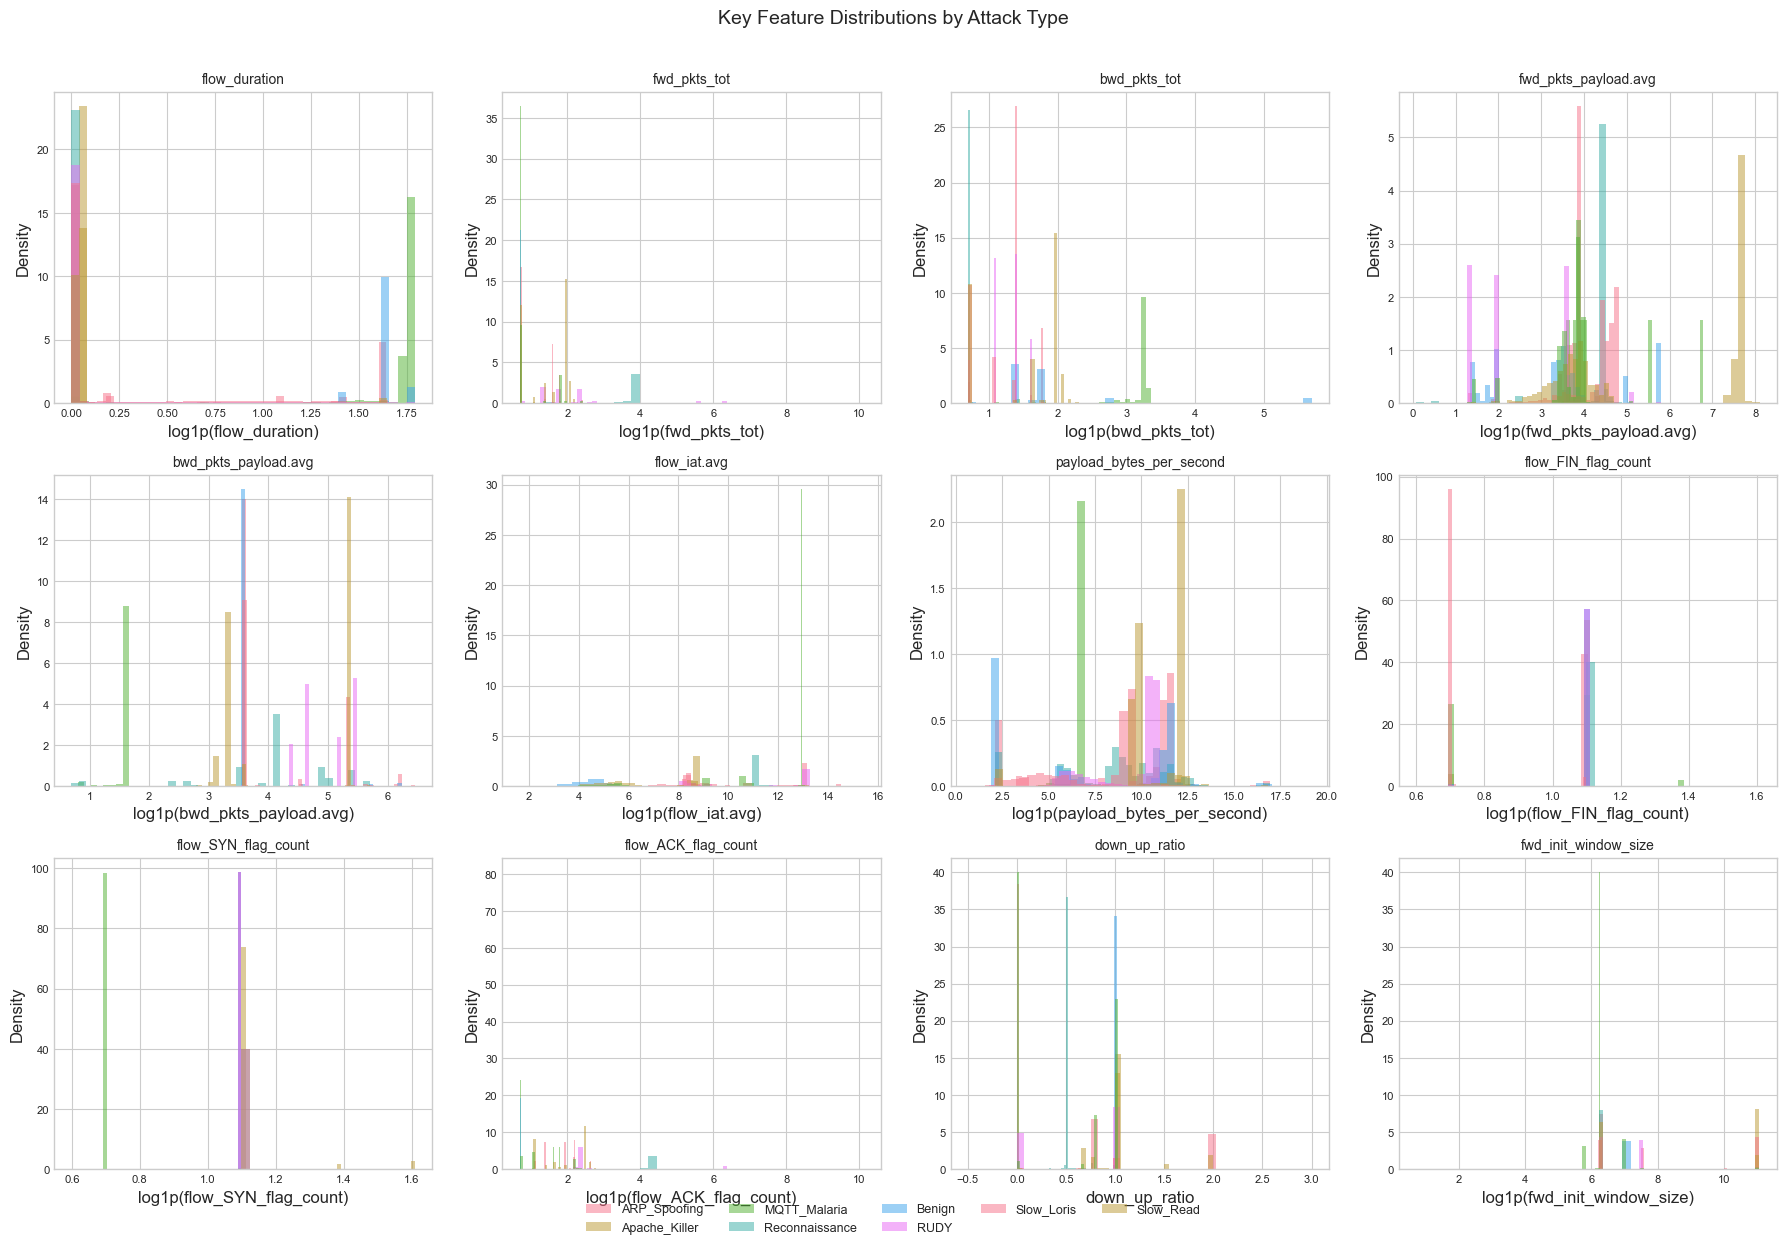

In [5]:
# Key features to visualize (representative from each group)
key_features = [
    'flow_duration', 'fwd_pkts_tot', 'bwd_pkts_tot',
    'fwd_pkts_payload.avg', 'bwd_pkts_payload.avg',
    'flow_iat.avg', 'payload_bytes_per_second',
    'flow_FIN_flag_count', 'flow_SYN_flag_count', 'flow_ACK_flag_count',
    'down_up_ratio', 'fwd_init_window_size'
]

# Filter to only existing numeric features
key_features = [f for f in key_features if f in numeric_cols]

fig, axes = plt.subplots(3, 4, figsize=(18, 12))
axes = axes.flatten()

for i, feat in enumerate(key_features):
    ax = axes[i]
    data = df_flows[[feat, 'label']].copy()
    data[feat] = pd.to_numeric(data[feat], errors='coerce')
    data = data.dropna(subset=[feat])

    # Use log scale if values span many orders of magnitude
    vals = data[feat].replace([np.inf, -np.inf], np.nan).dropna()
    if vals.max() > 0 and vals.min() >= 0 and (vals.max() / max(vals.median(), 1e-10)) > 100:
        for label in data['label'].unique():
            subset = data[data['label'] == label][feat]
            subset = subset[subset > 0]
            if len(subset) > 0:
                ax.hist(np.log1p(subset), bins=40, alpha=0.5, label=label, density=True)
        ax.set_xlabel(f'log1p({feat})')
    else:
        for label in data['label'].unique():
            subset = data[data['label'] == label][feat]
            ax.hist(subset, bins=40, alpha=0.5, label=label, density=True)
        ax.set_xlabel(feat)

    ax.set_ylabel('Density')
    ax.set_title(feat, fontsize=10)
    ax.tick_params(labelsize=8)

# Remove unused axes
for j in range(len(key_features), len(axes)):
    axes[j].set_visible(False)

# Single legend
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=5, fontsize=9,
           bbox_to_anchor=(0.5, -0.02))
fig.suptitle('Key Feature Distributions by Attack Type', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

### 5.3 Boxplots — Key Features by Attack Type

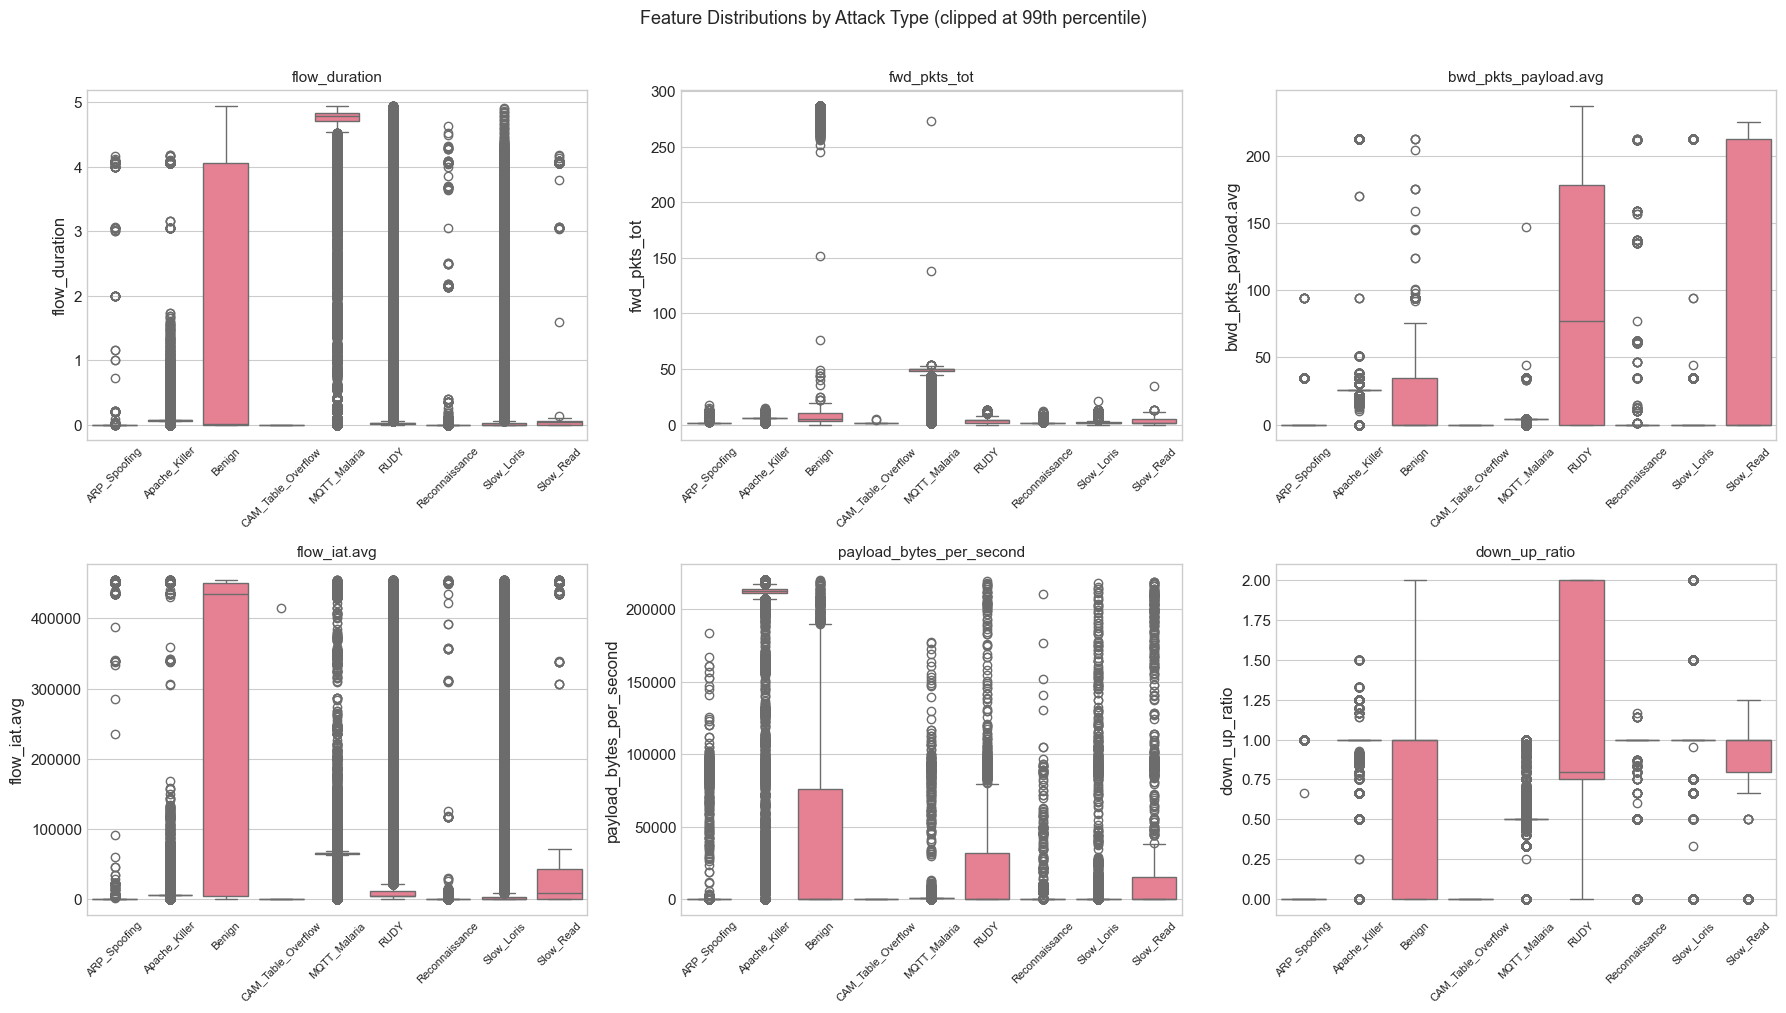

In [ ]:
box_features = ['flow_duration', 'fwd_pkts_tot', 'bwd_pkts_payload.avg',
                'flow_iat.avg', 'payload_bytes_per_second', 'down_up_ratio']
box_features = [f for f in box_features if f in numeric_cols]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, feat in enumerate(box_features):
    ax = axes[i]
    data = df_flows[[feat, 'label']].copy()
    data[feat] = pd.to_numeric(data[feat], errors='coerce')
    data = data.replace([np.inf, -np.inf], np.nan).dropna()

    # Clip extreme outliers for readability (99th percentile)
    q99 = data[feat].quantile(0.99)
    data_clipped = data[data[feat] <= q99]

    sns.boxplot(data=data_clipped, x='label', y=feat, ax=ax,
                order=sorted(data_clipped['label'].unique()))
    ax.set_title(feat, fontsize=11)
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=45, labelsize=8)

for j in range(len(box_features), len(axes)):
    axes[j].set_visible(False)

fig.suptitle('Feature Distributions by Attack Type (clipped at 99th percentile)', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

### 5.4 Correlation Analysis

Heatmap of feature correlations and identification of highly correlated pairs (|r| > 0.9).

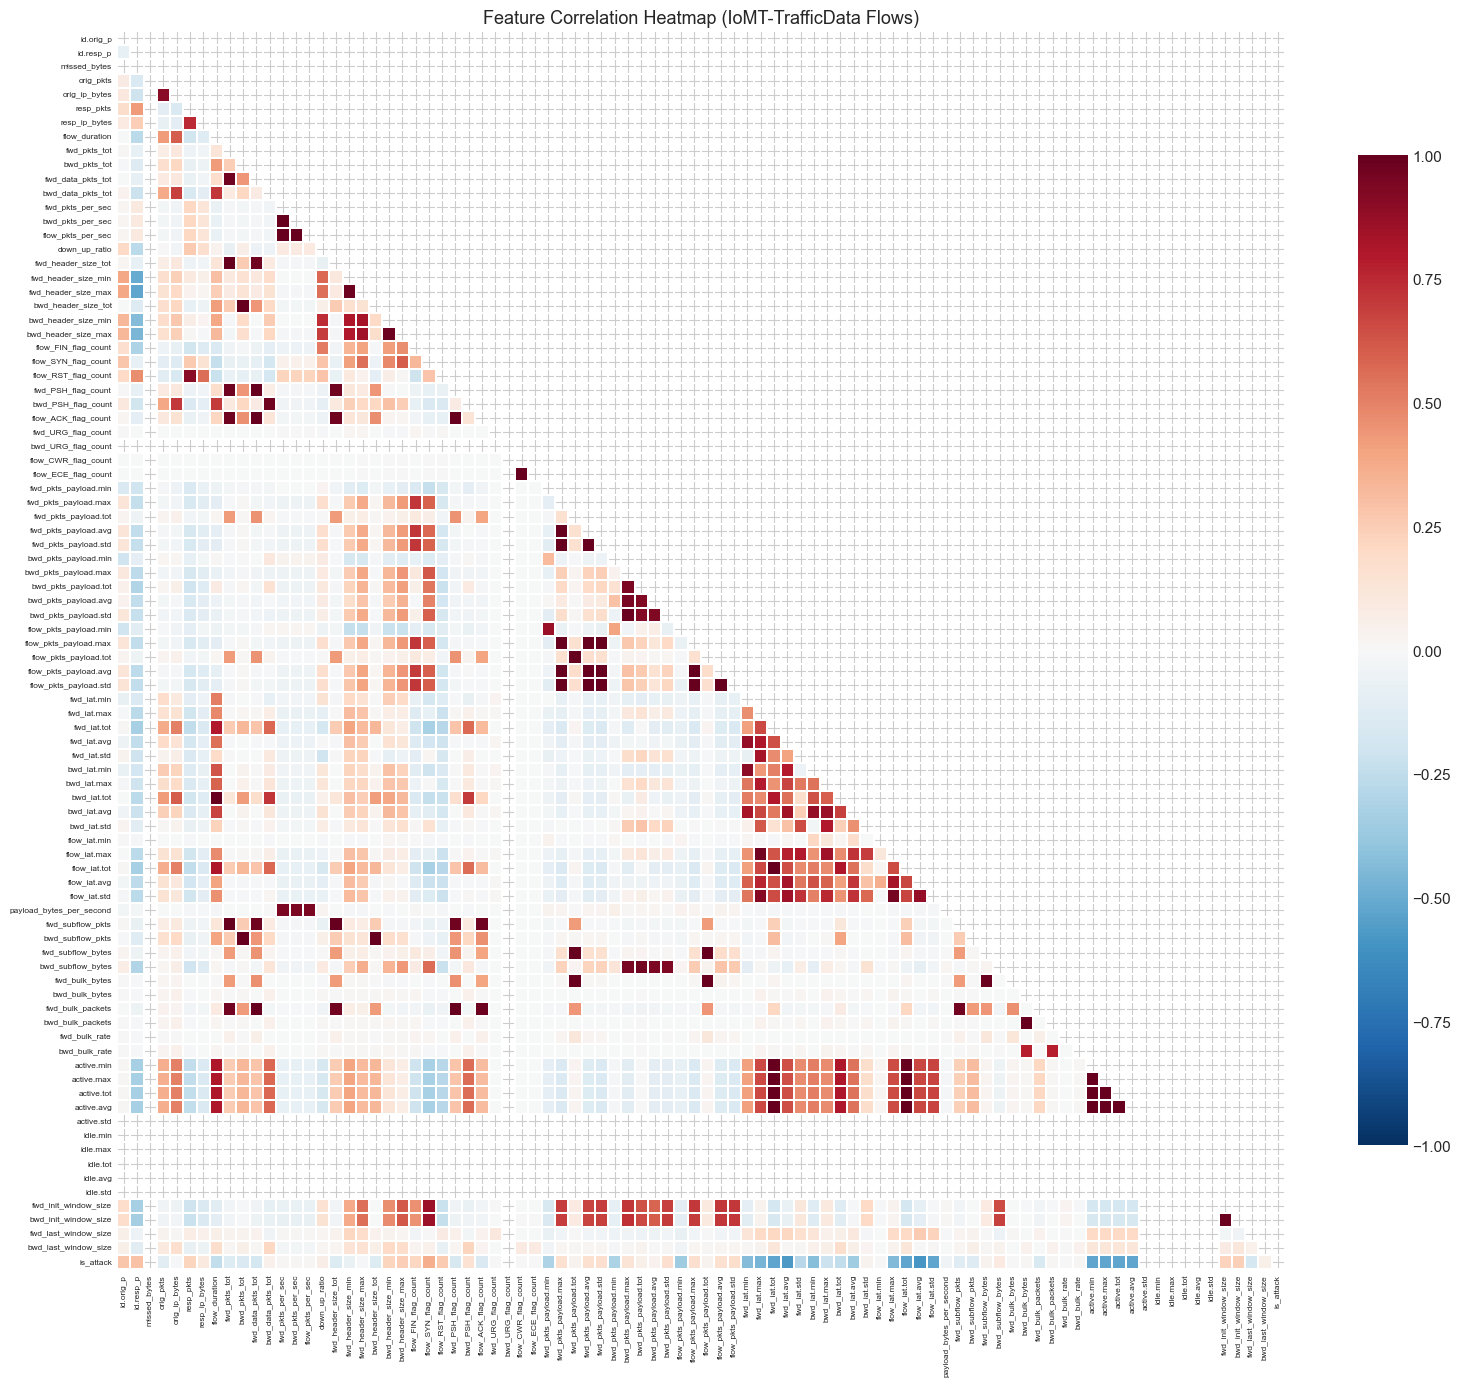


Highly correlated feature pairs (|r| > 0.9)
Found 88 pairs with |r| > 0.9

  fwd_pkts_per_sec                    ↔ flow_pkts_per_sec                    r=+1.0000
  bwd_pkts_per_sec                    ↔ flow_pkts_per_sec                    r=+1.0000
  flow_CWR_flag_count                 ↔ flow_ECE_flag_count                  r=+1.0000
  fwd_pkts_payload.tot                ↔ flow_pkts_payload.tot                r=+1.0000
  fwd_pkts_payload.tot                ↔ fwd_subflow_bytes                    r=+1.0000
  flow_pkts_payload.tot               ↔ fwd_subflow_bytes                    r=+1.0000
  flow_iat.tot                        ↔ active.min                           r=+1.0000
  flow_iat.tot                        ↔ active.max                           r=+1.0000
  flow_iat.tot                        ↔ active.tot                           r=+1.0000
  flow_iat.tot                        ↔ active.avg                           r=+1.0000
  bwd_bulk_bytes                      ↔ bwd_bulk_packe

In [ ]:
# Compute correlation on numeric features (sample for speed)
sample_for_corr = df_flows[numeric_cols].sample(n=min(100_000, len(df_flows)), random_state=42)
corr_matrix = sample_for_corr.corr()

# Heatmap
fig, ax = plt.subplots(figsize=(16, 14))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, cmap='RdBu_r', center=0,
            vmin=-1, vmax=1, ax=ax, xticklabels=True, yticklabels=True,
            linewidths=0.1, cbar_kws={'shrink': 0.8})
ax.set_title('Feature Correlation Heatmap (IoMT-TrafficData Flows)', fontsize=13)
ax.tick_params(labelsize=6)
plt.tight_layout()
plt.show()

# Highly correlated pairs (|r| > 0.9)
print('\nHighly correlated feature pairs (|r| > 0.9)')
print('=' * 70)
high_corr = []
for i in range(len(corr_matrix.columns)):
    for j in range(i + 1, len(corr_matrix.columns)):
        r = corr_matrix.iloc[i, j]
        if abs(r) > 0.9:
            high_corr.append((corr_matrix.columns[i], corr_matrix.columns[j], round(r, 4)))

high_corr.sort(key=lambda x: abs(x[2]), reverse=True)
print(f'Found {len(high_corr)} pairs with |r| > 0.9\n')
for f1, f2, r in high_corr[:25]:
    print(f'  {f1:35s} ↔ {f2:35s}  r={r:+.4f}')

In [ ]:
print('Column names (first 30 and last 5):')
cols = list(df_flows.columns)
for c in cols[:30]:
    print(f'  {c}')
print('  ...')
for c in cols[-5:]:
    print(f'  {c}')

if 'is_attack' in df_flows.columns:
    print('\nBinary label (is_attack) distribution:')
    print(df_flows['is_attack'].value_counts())

Column names (first 30 and last 5):
  id.orig_h
  id.orig_p
  id.resp_h
  id.resp_p
  proto
  service
  duration
  orig_bytes
  resp_bytes
  conn_state
  local_orig
  local_resp
  missed_bytes
  history
  orig_pkts
  orig_ip_bytes
  resp_pkts
  resp_ip_bytes
  tunnel_parents
  flow_duration
  fwd_pkts_tot
  bwd_pkts_tot
  fwd_data_pkts_tot
  bwd_data_pkts_tot
  fwd_pkts_per_sec
  bwd_pkts_per_sec
  flow_pkts_per_sec
  down_up_ratio
  fwd_header_size_tot
  fwd_header_size_min
  ...
  bwd_last_window_size
  traffic
  is_attack
  label
  source_file

Binary label (is_attack) distribution:
is_attack
1    769141
0    200000
Name: count, dtype: int64


## 6. Label Analysis & Attack Taxonomy

Distribution of **binary** (Benign vs Attack) and **multiclass** (attack type) labels.

### 6.1 Class Imbalance Analysis

Class Imbalance Analysis
Largest class:  CAM_Table_Overflow (200,000 rows)
Smallest class: Slow_Read (9,014 rows)
Imbalance ratio (max/min): 22.2:1

Per-class ratios (relative to smallest class):
  CAM_Table_Overflow                200,000  ratio:   22.2x
  Reconnaissance                    200,000  ratio:   22.2x
  Benign                            200,000  ratio:   22.2x
  RUDY                              131,081  ratio:   14.5x
  Apache_Killer                      84,579  ratio:    9.4x
  MQTT_Malaria                       69,623  ratio:    7.7x
  Slow_Loris                         63,608  ratio:    7.1x
  ARP_Spoofing                       11,236  ratio:    1.2x
  Slow_Read                           9,014  ratio:    1.0x

Binary: Benign=200,000 vs Attack=769,141
Attack/Benign ratio: 3.85:1


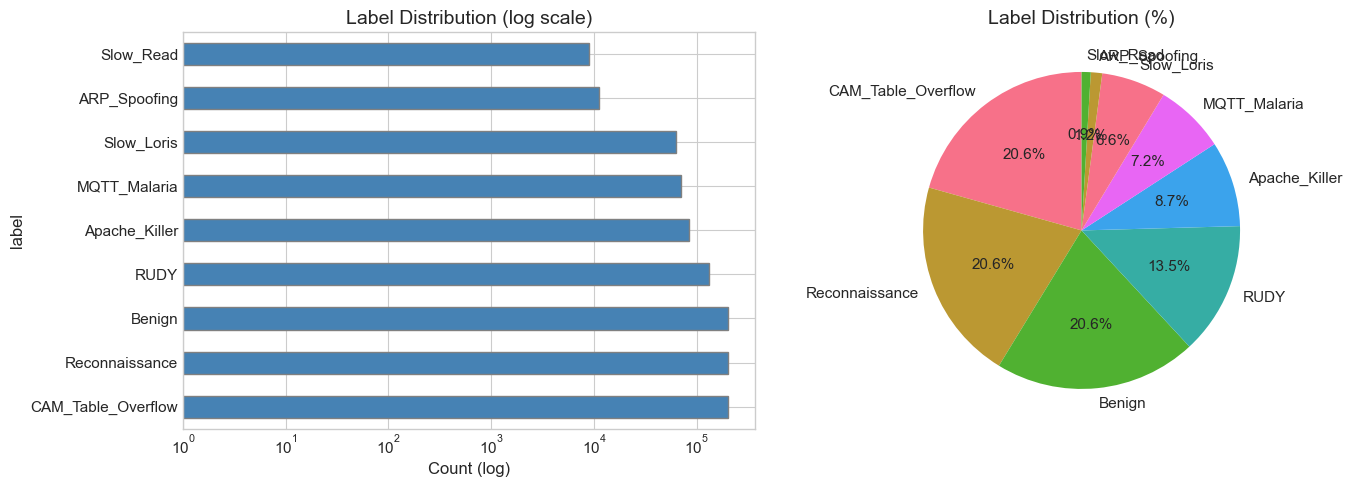

In [ ]:
# Class imbalance analysis
label_counts = df_flows['label'].value_counts()
min_class = label_counts.min()
max_class = label_counts.max()

print('Class Imbalance Analysis')
print('=' * 60)
print(f'Largest class:  {label_counts.idxmax()} ({max_class:,} rows)')
print(f'Smallest class: {label_counts.idxmin()} ({min_class:,} rows)')
print(f'Imbalance ratio (max/min): {max_class/min_class:.1f}:1')
print()

# Per-class imbalance ratios
print('Per-class ratios (relative to smallest class):')
for lbl, cnt in label_counts.items():
    ratio = cnt / min_class
    print(f'  {lbl:30s} {cnt:>10,}  ratio: {ratio:6.1f}x')

# Binary imbalance
n_benign = label_counts.get('Benign', 0)
n_attack = label_counts.sum() - n_benign
print(f'\nBinary: Benign={n_benign:,} vs Attack={n_attack:,}')
print(f'Attack/Benign ratio: {n_attack/max(n_benign,1):.2f}:1')

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Log-scale bar chart
label_counts.plot(kind='barh', ax=axes[0], color='steelblue', edgecolor='gray', log=True)
axes[0].set_title('Label Distribution (log scale)')
axes[0].set_xlabel('Count (log)')

# Percentage pie chart
label_counts.plot(kind='pie', ax=axes[1], autopct='%1.1f%%', startangle=90)
axes[1].set_title('Label Distribution (%)')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

## 6b. Data Quality Analysis

Zero-variance features, near-zero-variance features, and skewness analysis for the numeric feature set.

In [ ]:
# ── Data Quality Analysis ──
print('Data Quality Analysis')
print('=' * 60)

# Zero-variance features
variances = df_flows[numeric_cols].var()
zero_var = variances[variances == 0]
print(f'\nZero-variance features: {len(zero_var)}')
if len(zero_var) > 0:
    for f in zero_var.index:
        print(f'  • {f} (constant value: {df_flows[f].iloc[0]})')

# Near-zero-variance (>95% same value)
print(f'\nNear-zero-variance features (>95% identical values):')
nzv_count = 0
for col in numeric_cols:
    most_common_pct = df_flows[col].value_counts(normalize=True).iloc[0] * 100
    if most_common_pct > 95:
        nzv_count += 1
        print(f'  • {col:40s} {most_common_pct:.1f}% identical')
print(f'  Total: {nzv_count}')

# Features with >90% zero values
print(f'\nFeatures with >90% zero values:')
zero_heavy = 0
for col in numeric_cols:
    zero_pct = (df_flows[col] == 0).mean() * 100
    if zero_pct > 90:
        zero_heavy += 1
        print(f'  • {col:40s} {zero_pct:.1f}% zeros')
print(f'  Total: {zero_heavy}')

# Skewness (highly skewed features may need transformation)
print(f'\nHighly skewed features (|skew| > 5):')
skew = df_flows[numeric_cols].skew().sort_values(key=abs, ascending=False)
high_skew = skew[abs(skew) > 5]
print(f'  {len(high_skew)} features with |skew| > 5')
for f, s in high_skew.head(15).items():
    print(f'  • {f:40s} skew={s:+.2f}')

print(f'\n{"=" * 60}')
print(f'Summary:')
print(f'  Total numeric features:    {len(numeric_cols)}')
print(f'  Zero-variance:             {len(zero_var)}')
print(f'  Near-zero-variance (>95%): {nzv_count}')
print(f'  >90% zeros:                {zero_heavy}')
print(f'  Highly skewed (|s|>5):     {len(high_skew)}')
print(f'  → Potential removals:      {len(zero_var)} (zero-var) + review {nzv_count} near-zero-var')

Data Quality Analysis



Zero-variance features: 8
  • missed_bytes (constant value: 0)
  • bwd_URG_flag_count (constant value: 0)
  • active.std (constant value: 0.0)
  • idle.min (constant value: 0.0)
  • idle.max (constant value: 0.0)
  • idle.tot (constant value: 0.0)
  • idle.avg (constant value: 0.0)
  • idle.std (constant value: 0.0)

Near-zero-variance features (>95% identical values):
  • missed_bytes                             100.0% identical


  • fwd_URG_flag_count                       100.0% identical
  • bwd_URG_flag_count                       100.0% identical
  • flow_CWR_flag_count                      100.0% identical
  • flow_ECE_flag_count                      100.0% identical


  • fwd_bulk_bytes                           98.4% identical
  • bwd_bulk_bytes                           100.0% identical
  • fwd_bulk_packets                         98.4% identical
  • bwd_bulk_packets                         100.0% identical
  • fwd_bulk_rate                            98.4% identical
  • bwd_bulk_rate                            100.0% identical
  • active.std                               100.0% identical
  • idle.min                                 100.0% identical
  • idle.max                                 100.0% identical
  • idle.tot                                 100.0% identical
  • idle.avg                                 100.0% identical
  • idle.std                                 100.0% identical
  Total: 17

Features with >90% zero values:
  • missed_bytes                             100.0% zeros
  • fwd_URG_flag_count                       100.0% zeros
  • bwd_URG_flag_count                       100.0% zeros
  • flow_CWR_flag_count                 

  36 features with |skew| > 5
  • bwd_bulk_bytes                           skew=+881.02
  • bwd_bulk_rate                            skew=+728.13
  • flow_ECE_flag_count                      skew=+159.69
  • flow_CWR_flag_count                      skew=+159.69
  • fwd_subflow_pkts                         skew=+142.78
  • fwd_pkts_tot                             skew=+141.75
  • fwd_header_size_tot                      skew=+141.57
  • fwd_bulk_rate                            skew=+133.81
  • flow_ACK_flag_count                      skew=+113.27
  • fwd_bulk_packets                         skew=+112.28
  • fwd_data_pkts_tot                        skew=+111.35
  • fwd_PSH_flag_count                       skew=+111.24
  • payload_bytes_per_second                 skew=+103.60
  • bwd_pkts_per_sec                         skew=+89.89
  • flow_pkts_per_sec                        skew=+89.86

Summary:
  Total numeric features:    88
  Zero-variance:             8
  Near-zero-variance (>95%): 

Label distribution (multiclass)
  CAM_Table_Overflow                200,000  (20.64%)
  Reconnaissance                    200,000  (20.64%)
  Benign                            200,000  (20.64%)
  RUDY                              131,081  (13.53%)
  Apache_Killer                      84,579  ( 8.73%)
  MQTT_Malaria                       69,623  ( 7.18%)
  Slow_Loris                         63,608  ( 6.56%)
  ARP_Spoofing                       11,236  ( 1.16%)
  Slow_Read                           9,014  ( 0.93%)


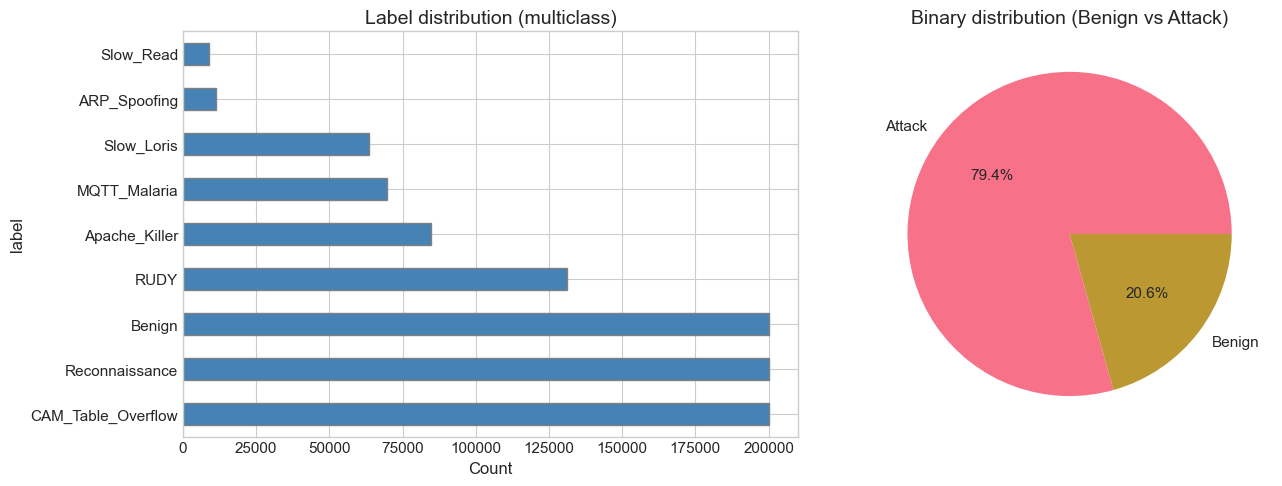

In [ ]:
print('Label distribution (multiclass)')
print('=' * 60)
label_counts = df_flows['label'].value_counts()
for lbl, cnt in label_counts.items():
    pct = 100 * cnt / len(df_flows)
    print(f'  {lbl:30s} {cnt:>10,}  ({pct:5.2f}%)')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
label_counts.plot(kind='barh', ax=axes[0], color='steelblue', edgecolor='gray')
axes[0].set_title('Label distribution (multiclass)')
axes[0].set_xlabel('Count')

binary = df_flows['label'].eq('Benign').map({True: 'Benign', False: 'Attack'})
binary.value_counts().plot(kind='pie', ax=axes[1], autopct='%1.1f%%', labels=['Attack', 'Benign'])
axes[1].set_title('Binary distribution (Benign vs Attack)')
plt.tight_layout()
plt.show()

## 7. Packet vs Flow Comparison Note

The paper compares **packet-based** and **flow-based** features for ML-based IDS:
- **Flow-based** features achieve on average **~3% better** performance for identifying malicious traffic than packet-based.
- For attack-type (multiclass) classification, flow-based features achieve **up to ~5% better** performance.

This supports our **flow-level integration** choice for the unified pipeline (CICIoT2023, CICIoMT2024, and IoMT-TrafficData flow data).

## 8. Summary & Key Findings

| Aspect | IoMT-TrafficData (Flows) |
|---|---|
| **Schema** | Zeek flow/conn-style (101 features: id.orig_h, duration, fwd_*, bwd_*, flow_*, IAT, flags, bulk, window sizes, active/idle) |
| **Feature extraction** | **Zeek (Bro)** — fundamentally different from the **DPKT window-based** approach used by CICIoT2023 and CICIoMT2024. Zeek creates per-connection flow records; DPKT aggregates over fixed packet windows. |
| **Labels** | Binary (`is_attack`: 0/1) and multiclass (9 classes from filename: Benign, ARP_Spoofing, Apache_Killer, CAM_Table_Overflow, MQTT_Malaria, Reconnaissance, RUDY, Slow_Loris, Slow_Read) |
| **Class imbalance** | Moderate (max/min ratio ~22:1). Less extreme than CICIoT2023 but still requires attention. |
| **Data quality** | No nulls, no infinities. Some zero-variance and near-zero-variance features to review. Highly skewed distributions common → log transforms recommended. |
| **Correlations** | Several highly correlated feature pairs (|r| > 0.9) exist → feature selection or dimensionality reduction needed. |
| **Protocols** | CoAP, MQTT, HTTP (paper); IP-based flow CSVs used here |
| **Integration** | Feature set differs fundamentally from CICIoT2023/CICIoMT2024 (Zeek vs DPKT). **Semantic feature mapping** required: identify conceptually equivalent features (flow duration, packet counts, byte counts, IAT, flags). Direct column matching impossible. |
| **Use for thesis** | Second IoMT-specific dataset. Enables **Phase 1** of the integration pipeline: unify two IoMT datasets (CICIoMT2024 + IoMT-TrafficData) before integrating with generic IoT (CICIoT2023) in Phase 2. |

### Important Observations for the Integration Pipeline

1. **Zeek vs DPKT**: The two feature extraction paradigms (Zeek flow-level vs DPKT window-based) mean that integration requires **semantic feature mapping**, not simple column alignment.
2. **Common semantic features** exist across schemas: flow duration, forward/backward packet counts, byte counts, inter-arrival times, and TCP flags — though at different granularity levels.
3. **101 features vs 39–45**: IoMT-TrafficData has significantly more features; the common integration schema will be a **subset** determined by semantic equivalence.
4. **No packet-level data needed**: Flow-based features achieve ~5% better performance (per paper), confirming our flow-level integration strategy.
5. **Class imbalance** is moderate here (~22:1) compared to extreme imbalance in CICIoT2023 (~5750:1), which affects sampling strategy during integration.
6. **Data quality is high**: No missing values, no infinities. The main concern is zero-variance/near-zero-variance features that should be removed.
7. **Overlapping attack types** with CICIoMT2024: ARP Spoofing, MQTT attacks, Reconnaissance, and DoS variants — enabling meaningful cross-dataset label harmonization.
8. **BLE and Packet-level data** from the full Zenodo archive are **not needed** for our flow-level integration pipeline.